In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.neighbors import NearestNeighbors

In [2]:
df = pd.read_csv("CC_Customer_Dataset.csv")

print("Dataset Shape:", df.shape)
print("\nDataset Columns:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

Dataset Shape: (660, 7)

Dataset Columns:
['Sl_No', 'Customer Key', 'Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']

First 5 Rows:


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


In [4]:
df = pd.read_csv("CC_Customer_Dataset.csv")

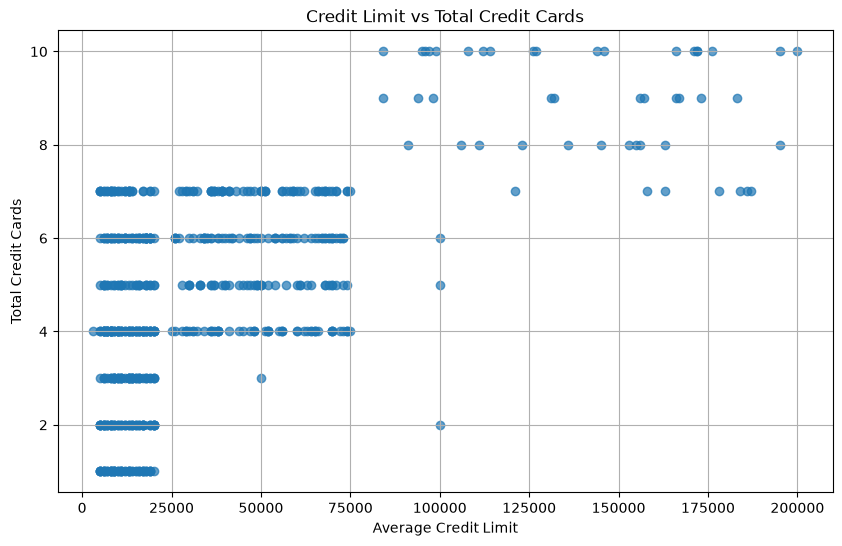

In [5]:
# Find the appropriate column names
columns_map = {
    col.lower().replace("_", "").replace(" ", ""): col
    for col in df.columns
}

credit_limit_col = columns_map.get("avgcreditlimit")
credit_card_col = columns_map.get("totalcreditcard")

if credit_card_col is None:
    credit_card_col = columns_map.get("totalcreditcards")

if credit_limit_col is None or credit_card_col is None:
    raise ValueError(
        "Required columns not found. "
        "Please check the dataset column names."
    )

# Select the two variables
plot_data = df[[credit_limit_col, credit_card_col]].dropna()

# Create scatterplot
plt.figure(figsize=(10, 6))

plt.scatter(
    plot_data[credit_limit_col],
    plot_data[credit_card_col],
    alpha=0.7,
    marker="o"
)

plt.title("Credit Limit vs Total Credit Cards")
plt.xlabel("Average Credit Limit")
plt.ylabel("Total Credit Cards")
plt.grid(True)
plt.show()

In [6]:
# Identify numeric columns
numeric_df = df.select_dtypes(include=np.number).copy()

# Remove identifier columns if they exist
id_keywords = [
    "sl_no",
    "customer_key",
    "customer_id",
    "id"
]

id_columns = [
    col for col in numeric_df.columns
    if any(keyword in col.lower() for keyword in id_keywords)
]

numeric_df = numeric_df.drop(columns=id_columns, errors="ignore")

# Handle missing values
numeric_df = numeric_df.replace([np.inf, -np.inf], np.nan)
numeric_df = numeric_df.dropna()

print("Features used for clustering:")
print(numeric_df.columns.tolist())

print("\nData shape:", numeric_df.shape)

display(numeric_df.head())

Features used for clustering:
['Customer Key', 'Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']

Data shape: (660, 6)


,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,87073,100000,2,1,1,0
1,38414,50000,3,0,10,9
2,17341,50000,7,1,3,4
3,40496,30000,5,1,1,4
4,47437,100000,6,0,12,3


In [7]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(numeric_df)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (660, 6)


In [8]:
sse = []
K = range(1, 11)

for k in K:
    kmeans_model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans_model.fit(X_scaled)
    sse.append(kmeans_model.inertia_)

print("Number of K values:", len(K))
print("Number of SSE values:", len(sse))

d:\conda\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
d:\conda\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
d:\conda\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
d:\conda\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. Y

Number of K values: 10
Number of SSE values: 10


d:\conda\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
d:\conda\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


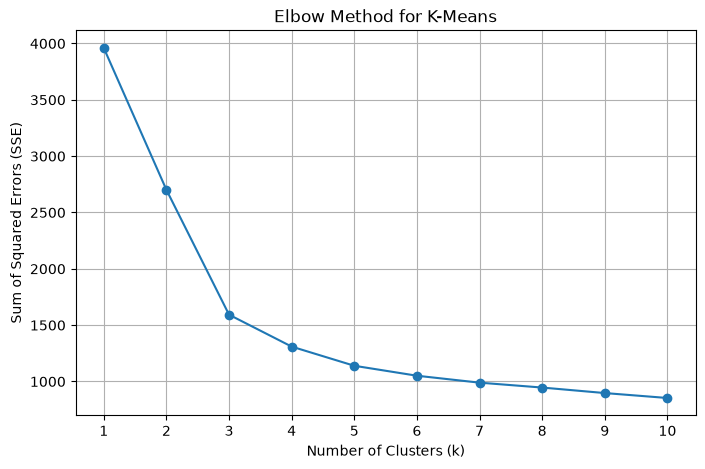

In [9]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(K),
    sse,
    marker="o",
    linestyle="-"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Sum of Squared Errors (SSE)")
plt.title("Elbow Method for K-Means")
plt.xticks(list(K))
plt.grid(True)
plt.show()

In [10]:
optimal_k = 3  # Replace with the value selected from the elbow plot

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

df_kmeans = df.loc[numeric_df.index].copy()
df_kmeans["KMeans_Cluster"] = kmeans_labels

print("Selected number of clusters:", optimal_k)
print("\nCluster distribution:")
print(df_kmeans["KMeans_Cluster"].value_counts().sort_index())

Selected number of clusters: 3

Cluster distribution:
KMeans_Cluster
0    386
1     50
2    224
Name: count, dtype: int64


d:\conda\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


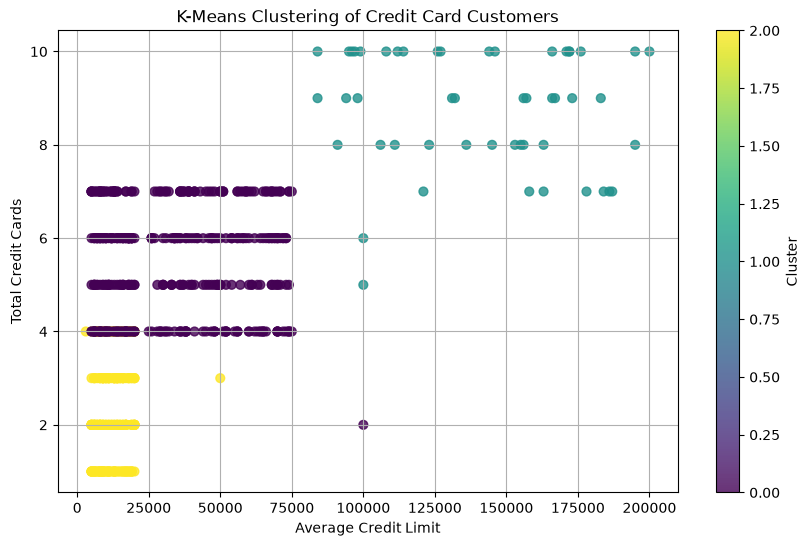

In [11]:
plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    df_kmeans[credit_limit_col],
    df_kmeans[credit_card_col],
    c=df_kmeans["KMeans_Cluster"],
    cmap="viridis",
    s=40,
    alpha=0.8
)

plt.xlabel("Average Credit Limit")
plt.ylabel("Total Credit Cards")
plt.title("K-Means Clustering of Credit Card Customers")

plt.colorbar(scatter, label="Cluster")
plt.grid(True)
plt.show()

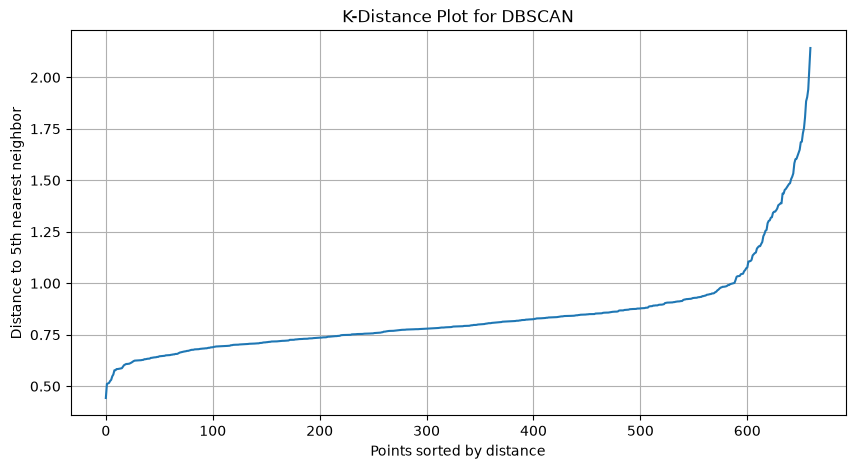

In [12]:
min_samples = 5

neighbors = NearestNeighbors(
    n_neighbors=min_samples
)

neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)

# Sort the distances to the k-th nearest neighbor
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(10, 5))

plt.plot(k_distances)

plt.xlabel("Points sorted by distance")
plt.ylabel(f"Distance to {min_samples}th nearest neighbor")
plt.title("K-Distance Plot for DBSCAN")
plt.grid(True)
plt.show()

In [13]:
dbscan = DBSCAN(
    eps=0.5,
    min_samples=min_samples
)

dbscan_labels = dbscan.fit_predict(X_scaled)

df_dbscan = df.loc[numeric_df.index].copy()
df_dbscan["DBSCAN_Cluster"] = dbscan_labels

print("DBSCAN cluster distribution:")
print(df_dbscan["DBSCAN_Cluster"].value_counts().sort_index())

n_clusters = len(set(dbscan_labels) - {-1})
n_noise = np.sum(dbscan_labels == -1)

print("\nNumber of clusters:", n_clusters)
print("Number of noise points:", n_noise)

DBSCAN cluster distribution:
DBSCAN_Cluster
-1    655
 0      5
Name: count, dtype: int64

Number of clusters: 1
Number of noise points: 655


In [14]:
eps_values = np.arange(0.1, 1.6, 0.1)

results = []

for eps_value in eps_values:
    model = DBSCAN(
        eps=eps_value,
        min_samples=min_samples
    )

    labels = model.fit_predict(X_scaled)

    n_clusters = len(set(labels) - {-1})
    n_noise = np.sum(labels == -1)

    results.append({
        "eps": round(eps_value, 2),
        "n_clusters": n_clusters,
        "n_noise": n_noise
    })

dbscan_results = pd.DataFrame(results)

display(dbscan_results)

,eps,n_clusters,n_noise
0,0.1,0,660
1,0.2,0,660
2,0.3,0,660
3,0.4,0,660
4,0.5,1,655
5,0.6,8,607
6,0.7,23,375
7,0.8,6,119
8,0.9,1,66
9,1.0,2,50


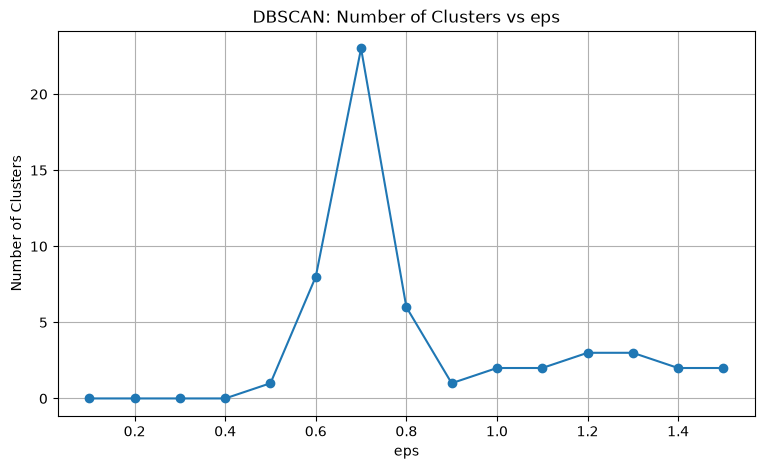

In [15]:
plt.figure(figsize=(9, 5))

plt.plot(
    dbscan_results["eps"],
    dbscan_results["n_clusters"],
    marker="o"
)

plt.xlabel("eps")
plt.ylabel("Number of Clusters")
plt.title("DBSCAN: Number of Clusters vs eps")
plt.grid(True)
plt.show()

In [16]:
# Identify non-noise samples
non_noise_mask = dbscan_labels != -1

X_evaluation = X_scaled[non_noise_mask]
labels_evaluation = dbscan_labels[non_noise_mask]

# Count valid clusters after excluding noise
valid_clusters = np.unique(labels_evaluation)
n_valid_clusters = len(valid_clusters)

print("Number of valid clusters:", n_valid_clusters)
print("Number of noise points:", np.sum(dbscan_labels == -1))

if 2 <= n_valid_clusters < len(labels_evaluation):

    silhouette = silhouette_score(
        X_evaluation,
        labels_evaluation
    )

    dbi = davies_bouldin_score(
        X_evaluation,
        labels_evaluation
    )

    print("Silhouette Score:", round(silhouette, 4))
    print("Davies-Bouldin Index:", round(dbi, 4))

else:
    print(
        "Silhouette Score and DBI cannot be reliably calculated "
        "because fewer than two valid clusters were found, "
        "or there are too few samples."
    )

Number of valid clusters: 1
Number of noise points: 655
Silhouette Score and DBI cannot be reliably calculated because fewer than two valid clusters were found, or there are too few samples.
